In [1]:
import urllib.request, json
from pathlib import Path

Path("splits").mkdir(exist_ok=True)
base = "https://raw.githubusercontent.com/ondyari/FaceForensics/master/dataset/splits/"
for s in ["train", "val", "test"]:
    urllib.request.urlretrieve(base + f"{s}.json", f"splits/{s}.json")
    print(s, len(json.load(open(f"splits/{s}.json"))), "pairs")
    

train 360 pairs
val 70 pairs
test 70 pairs


In [ ]:
%%writefile identity_split.py
import json
import random
import re
from pathlib import Path

NUMERIC = re.compile(r"^\d{3}$")


def load_official_splits(folder):
    
    id_to_split = {}
    for name in ("train", "val", "test"):
        pairs = json.loads((Path(folder) / f"{name}.json").read_text())
        for pair in pairs:
            for vid in pair:
                if id_to_split.setdefault(vid, name) != name:
                    raise ValueError(f"id {vid} appears in two splits")
    return id_to_split


def video_ids(path):
    
    parts = Path(path).stem.split("_")
    if parts and all(NUMERIC.match(p) for p in parts):
        return parts
    return []


def _group_key(path):
    
    return Path(path).stem.split("__")[0]


def split_by_identity(real_videos, fake_videos, id_to_split, seed=42,
                      ratios=(0.70, 0.15, 0.15)):
    out = {s: {"real": [], "fake": []} for s in ("train", "val", "test")}
    unmatched, cross = [], []

    for label, videos in (("real", real_videos), ("fake", fake_videos)):
        for v in videos:
            ids = video_ids(v)
            if not ids:
                unmatched.append((label, v))
                continue
            splits = {id_to_split.get(i) for i in ids}
            if len(splits) != 1 or None in splits:
                cross.append((label, v))  
                continue
            out[splits.pop()][label].append(v)

    
    groups = {}
    for label, v in unmatched:
        groups.setdefault(_group_key(v), []).append((label, v))
    keys = sorted(groups)
    random.Random(seed).shuffle(keys)
    n = len(keys)
    a, b = int(n * ratios[0]), int(n * (ratios[0] + ratios[1]))
    for i, k in enumerate(keys):
        s = "train" if i < a else "val" if i < b else "test"
        for label, v in groups[k]:
            out[s][label].append(v)

    print(f"Official-id videos placed: {sum(len(x['real'])+len(x['fake']) for x in out.values()) - len(unmatched)}")
    print(f"Non-numeric names (grouped by actor pair): {len(unmatched)} in {len(groups)} groups")
    print(f"Dropped (ids span two splits or unknown): {len(cross)}")
    return out


def leakage_report(splits):
    
    where = {}
    for s, d in splits.items():
        for v in d["real"]:
            ids = video_ids(v)
            if ids:
                where[ids[0]] = s
    print("\nLeakage check (fake whose source ids are real videos in ANOTHER split):")
    for s, d in splits.items():
        checked = leaked = 0
        for v in d["fake"]:
            ids = video_ids(v)
            if not ids:
                continue
            checked += 1
            if any(where.get(i, s) != s for i in ids):
                leaked += 1
        pct = 100 * leaked / checked if checked else 0
        print(f"  {s:5s}: {leaked}/{checked} fakes leak ({pct:.1f}%)")

Writing identity_split.py


In [3]:
from pathlib import Path
from identity_split import load_official_splits, split_by_identity, leakage_report

DATASET_DIR = Path("/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23")
ORIGINAL_DIR = DATASET_DIR / "original"
FAKE_DIRS = [DATASET_DIR / n for n in
             ["DeepFakeDetection", "Deepfakes", "Face2Face", "FaceShifter", "FaceSwap", "NeuralTextures"]]
EXT = {".mp4", ".avi", ".mov", ".mkv"}

def find_videos(folder):
    return [p for p in Path(folder).rglob("*") if p.suffix.lower() in EXT]

real_videos = find_videos(ORIGINAL_DIR)
fake_videos = [v for f in FAKE_DIRS for v in find_videos(f)]
print("Real:", len(real_videos), " Fake:", len(fake_videos))

id_to_split = load_official_splits("splits")
splits = split_by_identity(real_videos, fake_videos, id_to_split, seed=42)
leakage_report(splits)

print()
for s in ["train", "val", "test"]:
    print(s, "real:", len(splits[s]["real"]), "fake:", len(splits[s]["fake"]))

Real: 1000  Fake: 6000
Official-id videos placed: 6000
Non-numeric names (grouped by actor pair): 1000 in 257 groups
Dropped (ids span two splits or unknown): 0

Leakage check (fake whose source ids are real videos in ANOTHER split):
  train: 0/3600 fakes leak (0.0%)
  val  : 0/700 fakes leak (0.0%)
  test : 0/700 fakes leak (0.0%)

train real: 720 fake: 4332
val real: 140 fake: 807
test real: 140 fake: 861


In [4]:
import pandas as pd

rows = []
for s in ["train", "val", "test"]:
    for label in ["real", "fake"]:
        for v in splits[s][label]:
            uid = "_".join(v.relative_to(DATASET_DIR).with_suffix("").parts)
            rows.append((str(v), uid, label, s))

df = pd.DataFrame(rows, columns=["video_path", "uid", "label", "split"])
df.to_csv("split_assignment.csv", index=False)
print(len(df), "videos saved")
print(df.groupby(["split", "label"]).size())

7000 videos saved
split  label
test   fake      861
       real      140
train  fake     4332
       real      720
val    fake      807
       real      140
dtype: int64


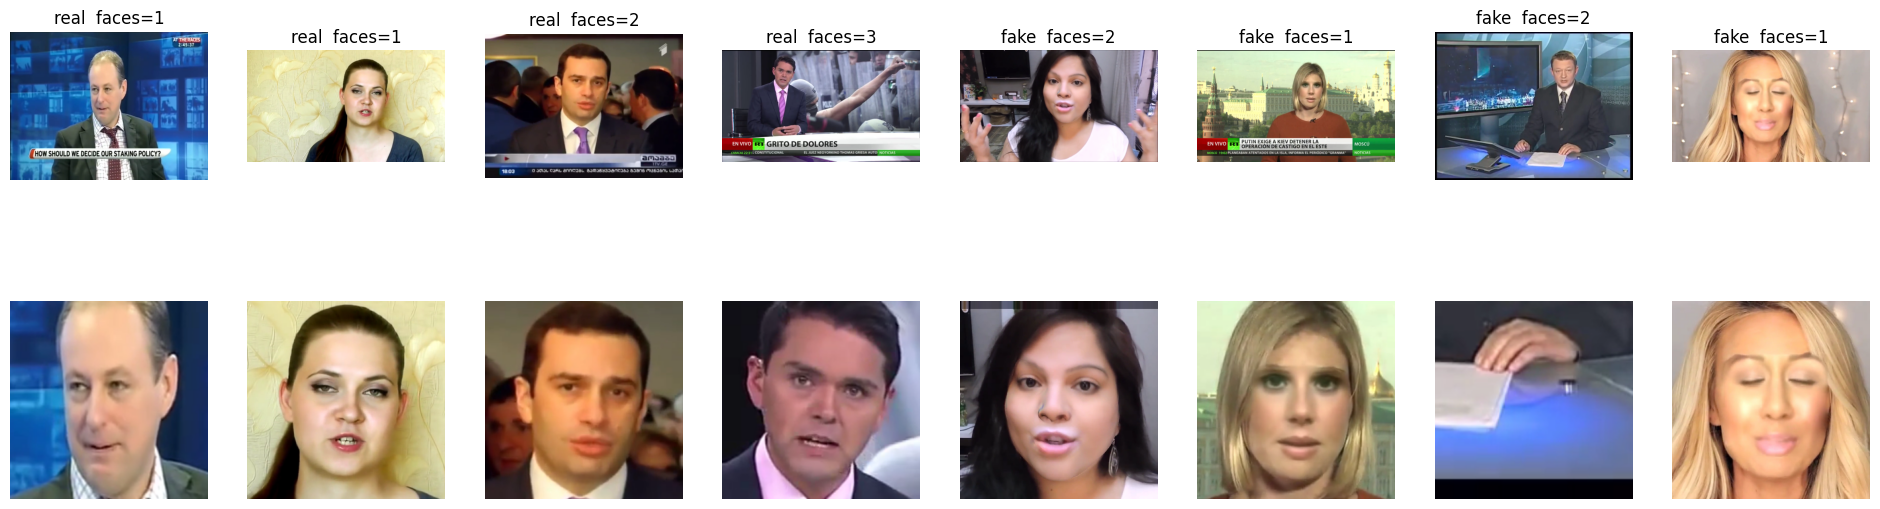

In [5]:
!pip install facenet-pytorch --no-deps -q

import cv2, torch, pandas as pd
import matplotlib.pyplot as plt
from facenet_pytorch import MTCNN

device = "cuda" if torch.cuda.is_available() else "cpu"
mtcnn = MTCNN(keep_all=True, device=device)

def crop_face(frame_rgb, box, margin=0.3, size=299):
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1) * (1 + margin)
    pad = int(side)
    padded = cv2.copyMakeBorder(frame_rgb, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    a, b = int(cx - side / 2) + pad, int(cy - side / 2) + pad
    crop = padded[b:b + int(side), a:a + int(side)]
    return cv2.resize(crop, (size, size))

def middle_frame(path):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if ok else None

df = pd.read_csv("split_assignment.csv")
train = df[df.split == "train"]
sample = pd.concat([train[train.label == "real"].sample(4, random_state=1),
                    train[train.label == "fake"].sample(4, random_state=1)])

fig, axes = plt.subplots(2, 8, figsize=(24, 7))
for i, (_, row) in enumerate(sample.iterrows()):
    frame = middle_frame(row.video_path)
    boxes, probs = mtcnn.detect(frame)
    axes[0, i].imshow(frame); axes[0, i].axis("off")
    axes[0, i].set_title(f"{row.label}  faces={0 if boxes is None else len(boxes)}")
    if boxes is not None:
        big = max(boxes, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))
        axes[1, i].imshow(crop_face(frame, big))
    axes[1, i].axis("off")
plt.show()

In [ ]:
import cv2, zipfile, time, numpy as np, pandas as pd, torch
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from facenet_pytorch import MTCNN

LIMIT = None          
FRAMES_PER_VIDEO = 10
MARGIN = 0.3
CROP_SIZE = 299
JPEG_QUALITY = 95

OUT_DIR = Path("/kaggle/working/face_crops")
OUT_DIR.mkdir(exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
mtcnn = MTCNN(keep_all=True, device=device)
df = pd.read_csv("split_assignment.csv")


def crop_face(frame_rgb, box, margin=MARGIN, size=CROP_SIZE):
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1) * (1 + margin)
    pad = int(side)
    padded = cv2.copyMakeBorder(frame_rgb, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    a, b = int(cx - side / 2) + pad, int(cy - side / 2) + pad
    return cv2.resize(padded[b:b + int(side), a:a + int(side)], (size, size))


def read_frames(video_path):
    cap = cv2.VideoCapture(video_path)
    frames = []
    if cap.isOpened():
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total > 0:
            for i, idx in enumerate(np.linspace(0, total - 1, FRAMES_PER_VIDEO, dtype=int)):
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
                ok, f = cap.read()
                if ok:
                    frames.append((i, cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
    cap.release()
    return frames


def detect(imgs):
    try:
        return mtcnn.detect(np.stack(imgs))
    except RuntimeError:                      
        torch.cuda.empty_cache()
        boxes, probs = [], []
        for im in imgs:
            b, p = mtcnn.detect(im)
            boxes.append(b); probs.append(p)
        return boxes, probs


def process_split(split):
    sub = df[df.split == split]
    if LIMIT:
        sub = sub.sample(LIMIT, random_state=0)
    jobs = list(sub.itertuples())
    chunks = [jobs[i:i + 8] for i in range(0, len(jobs), 8)]
    rows, t0 = [], time.time()

    with zipfile.ZipFile(OUT_DIR / f"{split}.zip", "w", zipfile.ZIP_STORED) as zf, \
         ThreadPoolExecutor(4) as ex:
        submit = lambda ch: [ex.submit(read_frames, j.video_path) for j in ch]
        pending = submit(chunks[0]) if chunks else []
        for ci, ch in enumerate(tqdm(chunks, desc=split)):
            current = pending
            pending = submit(chunks[ci + 1]) if ci + 1 < len(chunks) else []
            for job, fut in zip(ch, current):
                frames = fut.result()
                if not frames:
                    print("No frames read:", job.video_path)
                    continue
                boxes_b, probs_b = detect([im for _, im in frames])
                for k, (i, img) in enumerate(frames):
                    row = dict(path=f"{split}/{job.label}/{job.uid}/frame_{i:03d}.jpg",
                               label=int(job.label == "fake"), split=split,
                               video_id=job.uid, frame_idx=i, face_found=False,
                               x1=np.nan, y1=np.nan, x2=np.nan, y2=np.nan, prob=np.nan)
                    boxes = boxes_b[k]
                    if boxes is not None and len(boxes):
                        j = int(np.argmax([(b[2] - b[0]) * (b[3] - b[1]) for b in boxes]))
                        crop = crop_face(img, boxes[j])
                        ok, buf = cv2.imencode(".jpg", cv2.cvtColor(crop, cv2.COLOR_RGB2BGR),
                                               [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
                        if ok:
                            zf.writestr(f"{job.label}/{job.uid}/frame_{i:03d}.jpg", buf.tobytes())
                            x1, y1, x2, y2 = boxes[j]
                            row.update(face_found=True, x1=x1, y1=y1, x2=x2, y2=y2,
                                       prob=float(probs_b[k][j]))
                    rows.append(row)

    out = pd.DataFrame(rows)
    out.to_csv(OUT_DIR / f"manifest_{split}.csv", index=False)
    secs = time.time() - t0
    print(f"{split}: {len(out)} frames, face found in {out.face_found.mean():.1%}, "
          f"{secs:.0f}s ({secs / max(len(jobs), 1):.1f}s per video)")
    return out


all_rows = [process_split(s) for s in ["val", "test", "train"]]
pd.concat(all_rows).to_csv(OUT_DIR / "manifest.csv", index=False)
print("Done")

val:   0%|          | 0/119 [00:00<?, ?it/s]

val: 9470 frames, face found in 99.8%, 1846s (1.9s per video)


test:   0%|          | 0/126 [00:00<?, ?it/s]

test: 10010 frames, face found in 99.9%, 2114s (2.1s per video)


train:   0%|          | 0/632 [00:00<?, ?it/s]

train: 50520 frames, face found in 99.9%, 10772s (2.1s per video)
Done
